**Example 1: Heating only the Electrons with One Triangular Event**


In [2]:

import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np

from astropy.visualization import quantity_support
import ebtelplusplus
from ebtelplusplus.models import (
    DemModel,
    HeatingModel,
    TriangularHeatingEvent
)

quantity_support()

<astropy.visualization.units.quantity_support.<locals>.MplQuantityConverter at 0x2333e7aa950>

In [3]:
#Heating event
event = TriangularHeatingEvent(0.0 * u.s,500 * u.s,0.04 * u.Unit("erg cm-3 s-1"))

#Heating Model
heating = HeatingModel(background=3.5e-5 * u.Unit("erg cm-3 s-1"),partition=1.0,events=[event])


In [4]:
result = ebtelplusplus.run(
    5e3 * u.s,
    40 * u.Mm,
    heating=heating,
    dem=DemModel(calculate_dem=True)
)

# 4. Extract quantities for plotting
time = result.time.to_value(u.s)
heat = result.heat.to_value(u.Unit("erg cm-3 s-1"))
te = result.electron_temperature.to_value(u.MK)
density = result.density.to_value(u.cm**-3)

# 5. Find maxima
i_te_max = np.argmax(te)
i_n_max = np.argmax(density)

t_te_max = time[i_te_max]
t_n_max = time[i_n_max]

# End of triangular heating event
t_end = 500.0


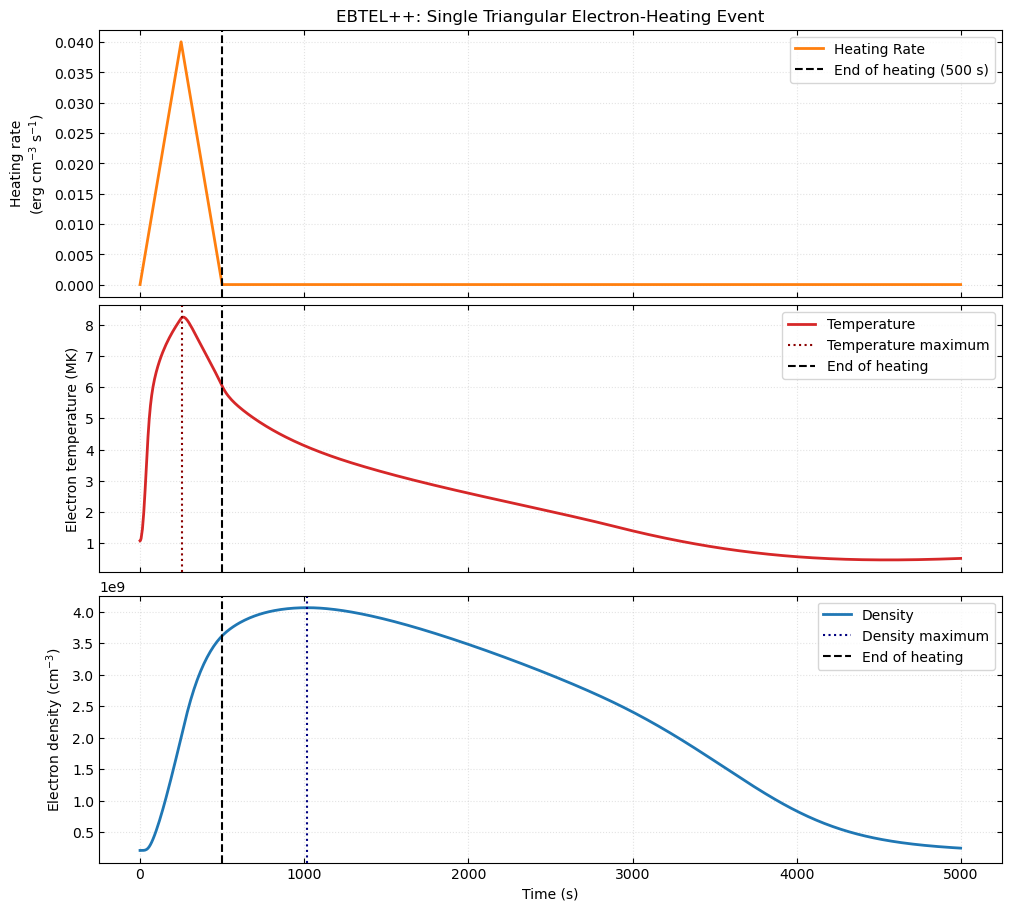

In [5]:
#Plotting
fig, axes = plt.subplots(3, 1,figsize=(10, 9),sharex=True,layout="constrained")

# 1. Heating rate

axes[0].plot( time, heat,color="tab:orange",linewidth=2,label='Heating Rate')

axes[0].axvline(t_end,color="black",linestyle="--", linewidth=1.5,label="End of heating (500 s)")

axes[0].set_ylabel( "Heating rate\n(erg cm$^{-3}$ s$^{-1}$)")

axes[0].set_title( "EBTEL++: Single Triangular Electron-Heating Event")

axes[0].legend(loc="best", frameon=True)


# 2. Electron temperature

axes[1].plot(time, te,color="tab:red",linewidth=2,label = 'Temperature')

axes[1].axvline( t_te_max,color="darkred",linestyle=":",linewidth=1.5,label="Temperature maximum")

axes[1].axvline(t_end,color="black",linestyle="--",linewidth=1.5, label="End of heating")

axes[1].set_ylabel("Electron temperature (MK)")
axes[1].legend(loc="best", frameon=True)



# 3. Density

axes[2].plot(time, density,color="tab:blue",linewidth=2,label='Density')

axes[2].axvline(t_n_max,color="navy",linestyle=":",linewidth=1.5,label="Density maximum")

axes[2].axvline( t_end,color="black",linestyle="--",linewidth=1.5,label="End of heating")

axes[2].set_ylabel("Electron density (cm$^{-3}$)")
axes[2].set_xlabel("Time (s)")
axes[2].legend(loc="best", frameon=True)


# Common formatting

for ax in axes:
    ax.grid(True, linestyle=":", alpha=0.35)
    ax.tick_params(direction="in", top=True, right=True)

plt.show()

In [6]:
#RESULTS 

# Simulation Input parameters

print(f"Half-length          : {40} Mm")
print(f"Background heating   : {3.5e-5:.2e} erg cm^-3 s^-1")
print(f"Pulse shape          : Triangular")
print(f"Pulse start time     : {0} s")
print(f"Pulse duration       : {500} s")
print(f"Peak heating rate    : {0.04} erg cm^-3 s^-1")
print(f"Heating partition    : {1.0}")

# Predicted results
print("\n--- Model Predictions ---")
print(f"Simulation end time  : {time[-1]:.1f} s")
print(f"End of heating       : {t_end:.1f} s")
print(f"Maximum temperature  : {te[i_te_max]:.3f} MK")
print(f"Temperature peak time: {t_te_max:.1f} s")
print(f"Maximum density      : {density[i_n_max]:.3e} cm^-3")
print(f"Density peak time    : {t_n_max:.1f} s")
print(f"Initial density : {density[0]:.3e} cm^-3")
print(f"Peak density    : {density[i_n_max]:.3e} cm^-3")
print(f"Final density   : {density[-1]:.3e} cm^-3")


Half-length          : 40 Mm
Background heating   : 3.50e-05 erg cm^-3 s^-1
Pulse shape          : Triangular
Pulse start time     : 0 s
Pulse duration       : 500 s
Peak heating rate    : 0.04 erg cm^-3 s^-1
Heating partition    : 1.0

--- Model Predictions ---
Simulation end time  : 4997.5 s
End of heating       : 500.0 s
Maximum temperature  : 8.240 MK
Temperature peak time: 258.3 s
Maximum density      : 4.066e+09 cm^-3
Density peak time    : 1017.5 s
Initial density : 2.059e+08 cm^-3
Peak density    : 4.066e+09 cm^-3
Final density   : 2.427e+08 cm^-3


**Experiment 1: 1 * Heating Duration (500s)**

In [8]:
#The rest heating rate and code is same forn 500s duration so , i am directly finding only the emission measure.

half_length = 40 * u.Mm
width = 10 * u.Mm

# square cross-section
area = width**2

#  one half-loop volume consistently
strand_volume = area * half_length

# Converting volume to cm^3
strand_volume_cm3 = strand_volume.to_value(u.cm**3)


# 2. Calculate volume emission measure


# Convert density to cm^-3
density_cm3 = np.asarray(density)


# Approximation: EM_V(t) = n_e(t)^2 * V

em_volume = density_cm3**2 * strand_volume_cm3
em_max_index = np.argmax(em_volume)

em_max = em_volume[em_max_index]
t_em_max = time[em_max_index]

print("FIXED STRAND GEOMETRY")
print(f"Half-length       : {half_length}")
print(f"Assumed width     : {width}")
print(f"Cross-sectional area: {area.to_value(u.cm**2):.3e} cm^2")
print(f"Half-loop volume  : {strand_volume_cm3:.3e} cm^3")

print("\nPEAK EMISSION MEASURE")
print(f"Peak volume EM    : {em_max:.3e} cm^-3")
print(f"Time of peak EM   : {t_em_max:.2f} s")


FIXED STRAND GEOMETRY
Half-length       : 40.0 Mm
Assumed width     : 10.0 Mm
Cross-sectional area: 1.000e+18 cm^2
Half-loop volume  : 4.000e+27 cm^3

PEAK EMISSION MEASURE
Peak volume EM    : 6.613e+46 cm^-3
Time of peak EM   : 1017.50 s


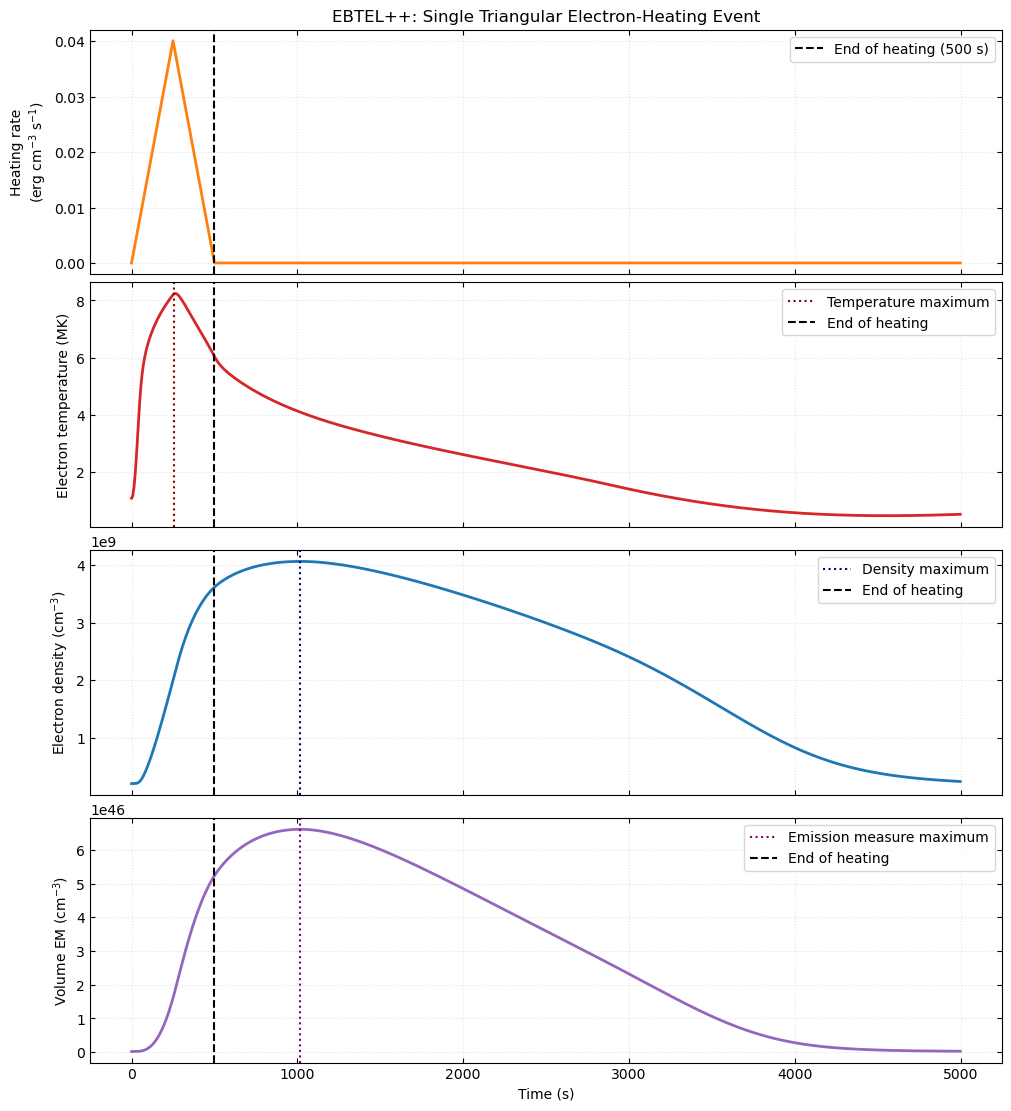

In [13]:
fig, axes = plt.subplots(4, 1,figsize=(10, 11),sharex=True,layout="constrained")

# Heating rate
axes[0].plot( time, heat,color="tab:orange",linewidth=2)
axes[0].axvline(t_end,color="black",linestyle="--",linewidth=1.5,label="End of heating (500 s)")
axes[0].set_ylabel("Heating rate\n(erg cm$^{-3}$ s$^{-1}$)")
axes[0].set_title("EBTEL++: Single Triangular Electron-Heating Event")
axes[0].legend(loc="best", frameon=True)

# Electron temperature
axes[1].plot(time, te,color="tab:red",linewidth=2)
axes[1].axvline(t_te_max,color="darkred",linestyle=":",linewidth=1.5,label="Temperature maximum")
axes[1].axvline(t_end,color="black",linestyle="--",linewidth=1.5,label="End of heating")
axes[1].set_ylabel("Electron temperature (MK)")
axes[1].legend(loc="best", frameon=True)

# Electron density
axes[2].plot(time, density,color="tab:blue",linewidth=2)
axes[2].axvline(t_n_max, color="navy", linestyle=":",linewidth=1.5, label="Density maximum")
axes[2].axvline(t_end, color="black",linestyle="--", linewidth=1.5,label="End of heating")
axes[2].set_ylabel("Electron density (cm$^{-3}$)")
axes[2].legend(loc="best", frameon=True)

# Volume emission measure
axes[3].plot(time, em_volume,color="tab:purple",linewidth=2)
axes[3].axvline( t_em_max,color="purple",linestyle=":", linewidth=1.5,label="Emission measure maximum")
axes[3].axvline(t_end,color="black",linestyle="--",linewidth=1.5,label="End of heating")
axes[3].set_ylabel("Volume EM (cm$^{-3}$)")
axes[3].set_xlabel("Time (s)")
axes[3].legend(loc="best", frameon=True)

# Consistent formatting across all panels
for ax in axes:
    ax.grid(True, linestyle=":", alpha=0.35)
    ax.tick_params(direction="in", top=True, right=True)

plt.show()

**Experiment 2: 0.5 * Heating Duration (250s)**

In [22]:
#Heating event
event = TriangularHeatingEvent(0.0 * u.s,250 * u.s,0.08 * u.Unit("erg cm-3 s-1"))

#Heating Model
heating = HeatingModel(background=3.5e-5 * u.Unit("erg cm-3 s-1"),partition=1.0,events=[event])
result = ebtelplusplus.run(
    5e3 * u.s,
    40 * u.Mm,
    heating=heating,
    dem=DemModel(calculate_dem=True)
)

# 4. Extract quantities for plotting
time = result.time.to_value(u.s)
heat = result.heat.to_value(u.Unit("erg cm-3 s-1"))
te = result.electron_temperature.to_value(u.MK)
density = result.density.to_value(u.cm**-3)

# 5. Find maxima
i_te_max = np.argmax(te)
i_n_max = np.argmax(density)

t_te_max = time[i_te_max]
t_n_max = time[i_n_max]

# End of triangular heating event
t_end = 250.0

#RESULTS 

# Simulation Input parameters

print(f"Half-length          : {40} Mm")
print(f"Background heating   : {3.5e-5:.2e} erg cm^-3 s^-1")
print(f"Pulse shape          : Triangular")
print(f"Pulse start time     : {0} s")
print(f"Pulse duration       : {250} s")
print(f"Peak heating rate    : {0.08} erg cm^-3 s^-1")
print(f"Heating partition    : {1.0}")

# Predicted results
print("\n--- Model Predictions ---")
print(f"Simulation end time  : {time[-1]:.1f} s")
print(f"End of heating       : {t_end:.1f} s")
print(f"Maximum temperature  : {te[i_te_max]:.3f} MK")
print(f"Temperature peak time: {t_te_max:.1f} s")
print(f"Maximum density      : {density[i_n_max]:.3e} cm^-3")
print(f"Density peak time    : {t_n_max:.1f} s")
print(f"Initial density : {density[0]:.3e} cm^-3")
print(f"Peak density    : {density[i_n_max]:.3e} cm^-3")
print(f"Final density   : {density[-1]:.3e} cm^-3")


Half-length          : 40 Mm
Background heating   : 3.50e-05 erg cm^-3 s^-1
Pulse shape          : Triangular
Pulse start time     : 0 s
Pulse duration       : 250 s
Peak heating rate    : 0.08 erg cm^-3 s^-1
Heating partition    : 1.0

--- Model Predictions ---
Simulation end time  : 4990.0 s
End of heating       : 250.0 s
Maximum temperature  : 10.314 MK
Temperature peak time: 135.0 s
Maximum density      : 4.216e+09 cm^-3
Density peak time    : 770.0 s
Initial density : 2.059e+08 cm^-3
Peak density    : 4.216e+09 cm^-3
Final density   : 2.104e+08 cm^-3


In [23]:
#Emission Measure
half_length = 40 * u.Mm
width = 10 * u.Mm

# square cross-section
area = width**2

#  one half-loop volume consistently
strand_volume = area * half_length

# Converting volume to cm^3
strand_volume_cm3 = strand_volume.to_value(u.cm**3)


# 2. Calculate volume emission measure


# Convert density to cm^-3
density_cm3 = np.asarray(density)


# Approximation: EM_V(t) = n_e(t)^2 * V

em_volume = density_cm3**2 * strand_volume_cm3
em_max_index = np.argmax(em_volume)

em_max = em_volume[em_max_index]
t_em_max = time[em_max_index]

print("FIXED STRAND GEOMETRY")
print(f"Half-length       : {half_length}")
print(f"Assumed width     : {width}")
print(f"Cross-sectional area: {area.to_value(u.cm**2):.3e} cm^2")
print(f"Half-loop volume  : {strand_volume_cm3:.3e} cm^3")

print("\nPEAK EMISSION MEASURE")
print(f"Peak volume EM    : {em_max:.3e} cm^-3")
print(f"Time of peak EM   : {t_em_max:.2f} s")


FIXED STRAND GEOMETRY
Half-length       : 40.0 Mm
Assumed width     : 10.0 Mm
Cross-sectional area: 1.000e+18 cm^2
Half-loop volume  : 4.000e+27 cm^3

PEAK EMISSION MEASURE
Peak volume EM    : 7.110e+46 cm^-3
Time of peak EM   : 770.00 s


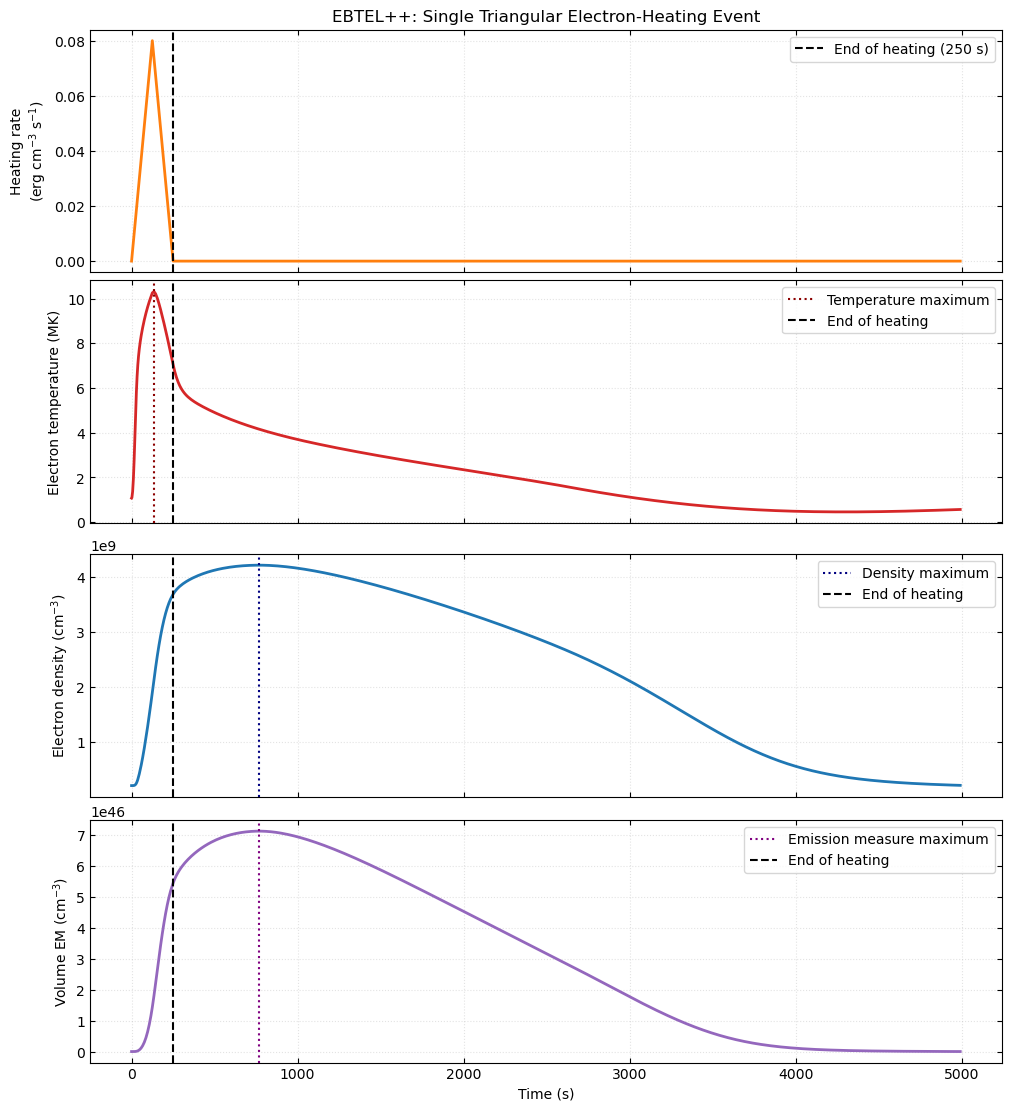

In [24]:
fig, axes = plt.subplots(4, 1,figsize=(10, 11),sharex=True,layout="constrained")

# Heating rate
axes[0].plot( time, heat,color="tab:orange",linewidth=2)
axes[0].axvline(t_end,color="black",linestyle="--",linewidth=1.5,label="End of heating (250 s)")
axes[0].set_ylabel("Heating rate\n(erg cm$^{-3}$ s$^{-1}$)")
axes[0].set_title("EBTEL++: Single Triangular Electron-Heating Event")
axes[0].legend(loc="best", frameon=True)

# Electron temperature
axes[1].plot(time, te,color="tab:red",linewidth=2)
axes[1].axvline(t_te_max,color="darkred",linestyle=":",linewidth=1.5,label="Temperature maximum")
axes[1].axvline(t_end,color="black",linestyle="--",linewidth=1.5,label="End of heating")
axes[1].set_ylabel("Electron temperature (MK)")
axes[1].legend(loc="best", frameon=True)

# Electron density
axes[2].plot(time, density,color="tab:blue",linewidth=2)
axes[2].axvline(t_n_max, color="navy", linestyle=":",linewidth=1.5, label="Density maximum")
axes[2].axvline(t_end, color="black",linestyle="--", linewidth=1.5,label="End of heating")
axes[2].set_ylabel("Electron density (cm$^{-3}$)")
axes[2].legend(loc="best", frameon=True)

# Volume emission measure
axes[3].plot(time, em_volume,color="tab:purple",linewidth=2)
axes[3].axvline( t_em_max,color="purple",linestyle=":", linewidth=1.5,label="Emission measure maximum")
axes[3].axvline(t_end,color="black",linestyle="--",linewidth=1.5,label="End of heating")
axes[3].set_ylabel("Volume EM (cm$^{-3}$)")
axes[3].set_xlabel("Time (s)")
axes[3].legend(loc="best", frameon=True)

# Consistent formatting across all panels
for ax in axes:
    ax.grid(True, linestyle=":", alpha=0.35)
    ax.tick_params(direction="in", top=True, right=True)

plt.show()

**Experiment 3: Heating duration 1500 seconds**

In [25]:
#Heating event
event = TriangularHeatingEvent(0.0 * u.s,1500 * u.s,0.01333 * u.Unit("erg cm-3 s-1"))

#Heating Model
heating = HeatingModel(background=3.5e-5 * u.Unit("erg cm-3 s-1"),partition=1.0,events=[event])
result = ebtelplusplus.run(
    5e3 * u.s,
    40 * u.Mm,
    heating=heating,
    dem=DemModel(calculate_dem=True)
)

# 4. Extract quantities for plotting
time = result.time.to_value(u.s)
heat = result.heat.to_value(u.Unit("erg cm-3 s-1"))
te = result.electron_temperature.to_value(u.MK)
density = result.density.to_value(u.cm**-3)

# 5. Find maxima
i_te_max = np.argmax(te)
i_n_max = np.argmax(density)

t_te_max = time[i_te_max]
t_n_max = time[i_n_max]

# End of triangular heating event
t_end = 1500.0

#RESULTS 

# Simulation Input parameters

print(f"Half-length          : {40} Mm")
print(f"Background heating   : {3.5e-5:.2e} erg cm^-3 s^-1")
print(f"Pulse shape          : Triangular")
print(f"Pulse start time     : {0} s")
print(f"Pulse duration       : {1500} s")
print(f"Peak heating rate    : {0.01333} erg cm^-3 s^-1")
print(f"Heating partition    : {1.0}")

# Predicted results
print("\n--- Model Predictions ---")
print(f"Simulation end time  : {time[-1]:.1f} s")
print(f"End of heating       : {t_end:.1f} s")
print(f"Maximum temperature  : {te[i_te_max]:.3f} MK")
print(f"Temperature peak time: {t_te_max:.1f} s")
print(f"Maximum density      : {density[i_n_max]:.3e} cm^-3")
print(f"Density peak time    : {t_n_max:.1f} s")
print(f"Initial density : {density[0]:.3e} cm^-3")
print(f"Peak density    : {density[i_n_max]:.3e} cm^-3")
print(f"Final density   : {density[-1]:.3e} cm^-3")


Half-length          : 40 Mm
Background heating   : 3.50e-05 erg cm^-3 s^-1
Pulse shape          : Triangular
Pulse start time     : 0 s
Pulse duration       : 1500 s
Peak heating rate    : 0.01333 erg cm^-3 s^-1
Heating partition    : 1.0

--- Model Predictions ---
Simulation end time  : 4990.0 s
End of heating       : 1500.0 s
Maximum temperature  : 6.088 MK
Temperature peak time: 800.0 s
Maximum density      : 3.853e+09 cm^-3
Density peak time    : 1750.0 s
Initial density : 2.059e+08 cm^-3
Peak density    : 3.853e+09 cm^-3
Final density   : 5.552e+08 cm^-3


In [26]:
#Emission Measure
half_length = 40 * u.Mm
width = 10 * u.Mm

# square cross-section
area = width**2

#  one half-loop volume consistently
strand_volume = area * half_length

# Converting volume to cm^3
strand_volume_cm3 = strand_volume.to_value(u.cm**3)


# 2. Calculate volume emission measure


# Convert density to cm^-3
density_cm3 = np.asarray(density)


# Approximation: EM_V(t) = n_e(t)^2 * V

em_volume = density_cm3**2 * strand_volume_cm3
em_max_index = np.argmax(em_volume)

em_max = em_volume[em_max_index]
t_em_max = time[em_max_index]

print("FIXED STRAND GEOMETRY")
print(f"Half-length       : {half_length}")
print(f"Assumed width     : {width}")
print(f"Cross-sectional area: {area.to_value(u.cm**2):.3e} cm^2")
print(f"Half-loop volume  : {strand_volume_cm3:.3e} cm^3")

print("\nPEAK EMISSION MEASURE")
print(f"Peak volume EM    : {em_max:.3e} cm^-3")
print(f"Time of peak EM   : {t_em_max:.2f} s")


FIXED STRAND GEOMETRY
Half-length       : 40.0 Mm
Assumed width     : 10.0 Mm
Cross-sectional area: 1.000e+18 cm^2
Half-loop volume  : 4.000e+27 cm^3

PEAK EMISSION MEASURE
Peak volume EM    : 5.940e+46 cm^-3
Time of peak EM   : 1750.00 s


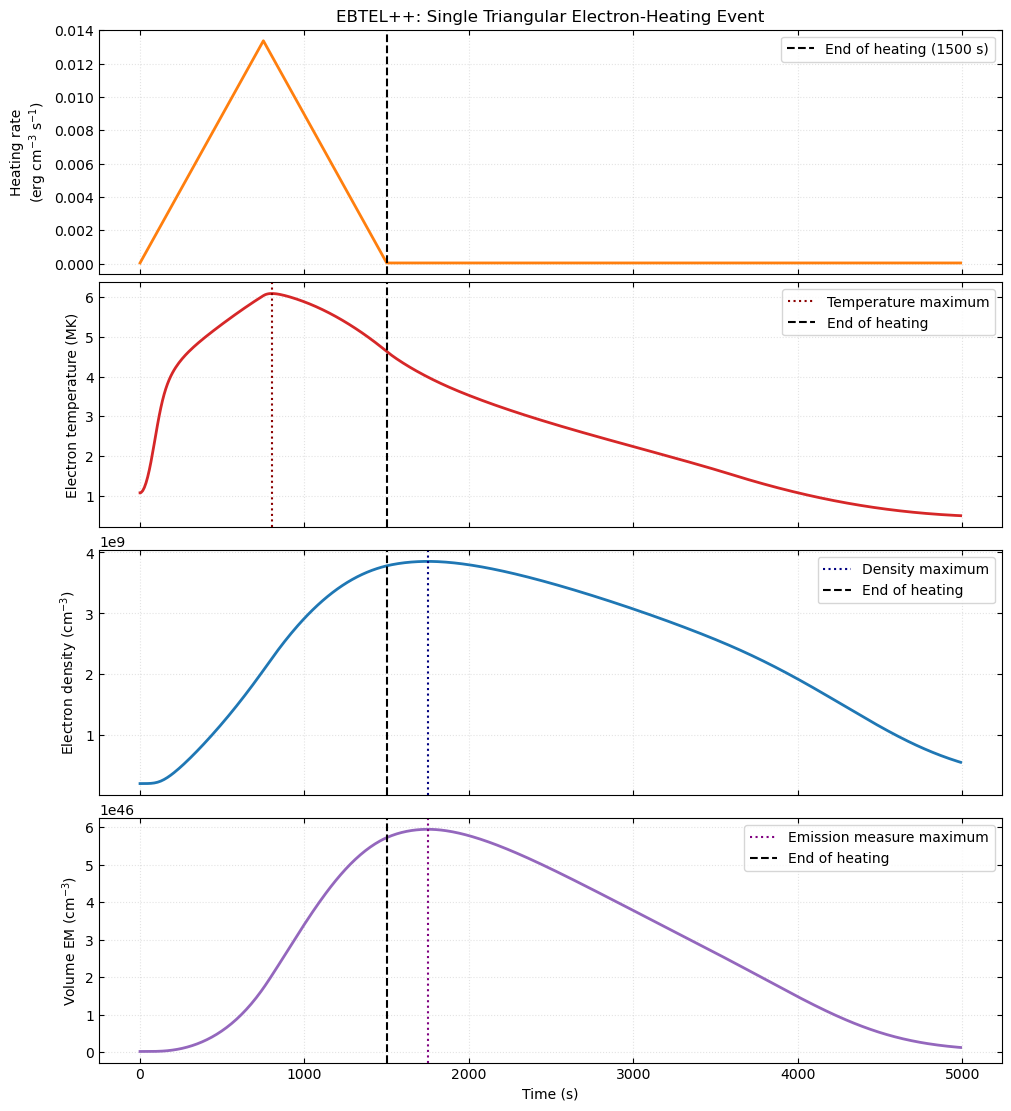

In [29]:
fig, axes = plt.subplots(4, 1,figsize=(10, 11),sharex=True,layout="constrained")

# Heating rate
axes[0].plot( time, heat,color="tab:orange",linewidth=2)
axes[0].axvline(t_end,color="black",linestyle="--",linewidth=1.5,label="End of heating (1500 s)")
axes[0].set_ylabel("Heating rate\n(erg cm$^{-3}$ s$^{-1}$)")
axes[0].set_title("EBTEL++: Single Triangular Electron-Heating Event")
axes[0].legend(loc="best", frameon=True)

# Electron temperature
axes[1].plot(time, te,color="tab:red",linewidth=2)
axes[1].axvline(t_te_max,color="darkred",linestyle=":",linewidth=1.5,label="Temperature maximum")
axes[1].axvline(t_end,color="black",linestyle="--",linewidth=1.5,label="End of heating")
axes[1].set_ylabel("Electron temperature (MK)")
axes[1].legend(loc="best", frameon=True)

# Electron density
axes[2].plot(time, density,color="tab:blue",linewidth=2)
axes[2].axvline(t_n_max, color="navy", linestyle=":",linewidth=1.5, label="Density maximum")
axes[2].axvline(t_end, color="black",linestyle="--", linewidth=1.5,label="End of heating")
axes[2].set_ylabel("Electron density (cm$^{-3}$)")
axes[2].legend(loc="best", frameon=True)

# Volume emission measure
axes[3].plot(time, em_volume,color="tab:purple",linewidth=2)
axes[3].axvline( t_em_max,color="purple",linestyle=":", linewidth=1.5,label="Emission measure maximum")
axes[3].axvline(t_end,color="black",linestyle="--",linewidth=1.5,label="End of heating")
axes[3].set_ylabel("Volume EM (cm$^{-3}$)")
axes[3].set_xlabel("Time (s)")
axes[3].legend(loc="best", frameon=True)

# Consistent formatting across all panels
for ax in axes:
    ax.grid(True, linestyle=":", alpha=0.35)
    ax.tick_params(direction="in", top=True, right=True)

plt.show()